In [110]:
from google.colab import files
uploaded = files.upload()

Saving online_retail_10_11.csv to online_retail_10_11 (1).csv


In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score


In [112]:
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["figure.dpi"] = 120

In [113]:
df = pd.read_csv("online_retail_10_11.csv")

In [114]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [115]:
df.shape

(541910, 8)

In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   UnitPrice    541910 non-null  float64
 6   CustomerID   406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [117]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [118]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [119]:
df = df.dropna(subset=['CustomerID'])
print(df.shape)

(406830, 8)


In [120]:
df['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(8905)

In [121]:
(df['Quantity'] < 0).sum()

np.int64(8905)

In [122]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [123]:
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

In [124]:
df.shape

(397885, 8)

In [125]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [126]:
df['InvoiceDate'].dtype

dtype('<M8[ns]')

In [127]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

In [128]:
df[['Quantity', 'UnitPrice', 'TotalAmount']].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [129]:
customer_spending = df.groupby('CustomerID')['TotalAmount'].sum()

In [130]:
customer_orders = df.groupby('CustomerID')['InvoiceNo'].nunique()

In [131]:
customer_quantity = df.groupby('CustomerID')['Quantity'].sum()

In [132]:
customer_products = df.groupby('CustomerID')['StockCode'].nunique()

In [133]:
customer_aov = customer_spending / customer_orders

In [134]:
df['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

In [135]:
customer_last_purchase = df.groupby('CustomerID')['InvoiceDate'].max()

In [136]:
reference_date = df['InvoiceDate'].max()

customer_recency = (reference_date - customer_last_purchase).dt.days

In [137]:
customer_data = pd.concat([
    customer_spending,
    customer_orders,
    customer_quantity,
    customer_products,
    customer_aov,
    customer_recency
], axis=1)

In [138]:
customer_data.head()

,TotalAmount,InvoiceNo,Quantity,StockCode,0,InvoiceDate
CustomerID,,,,,,
12346.0,77183.60,1,74215,1,77183.600000,325
12347.0,4310.00,7,2458,103,615.714286,1
12348.0,1797.24,4,2341,22,449.310000,74
12349.0,1757.55,1,631,73,1757.550000,18
12350.0,334.40,1,197,17,334.400000,309


In [139]:
customer_data.columns = [
    'TotalSpending',
    'NumberOfOrders',
    'TotalQuantity',
    'UniqueProducts',
    'AverageOrderValue',
    'Recency'
]

In [140]:
customer_data.isnull().sum()

,0
TotalSpending,0
NumberOfOrders,0
TotalQuantity,0
UniqueProducts,0
AverageOrderValue,0
Recency,0


In [141]:
customer_data.describe()

,TotalSpending,NumberOfOrders,TotalQuantity,UniqueProducts,AverageOrderValue,Recency
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,2054.270609,4.272015,1191.289304,61.501153,419.167327,91.536422
std,8989.229895,7.697998,5046.081512,85.366768,1796.537828,100.014169
min,3.750000,1.000000,1.000000,1.000000,3.450000,0.000000
25%,307.415000,1.000000,160.000000,16.000000,178.625000,17.000000
50%,674.485000,2.000000,379.000000,35.000000,293.900000,50.000000
75%,1661.740000,5.000000,992.750000,77.000000,430.113750,141.000000
max,280206.020000,209.000000,196915.000000,1787.000000,84236.250000,373.000000


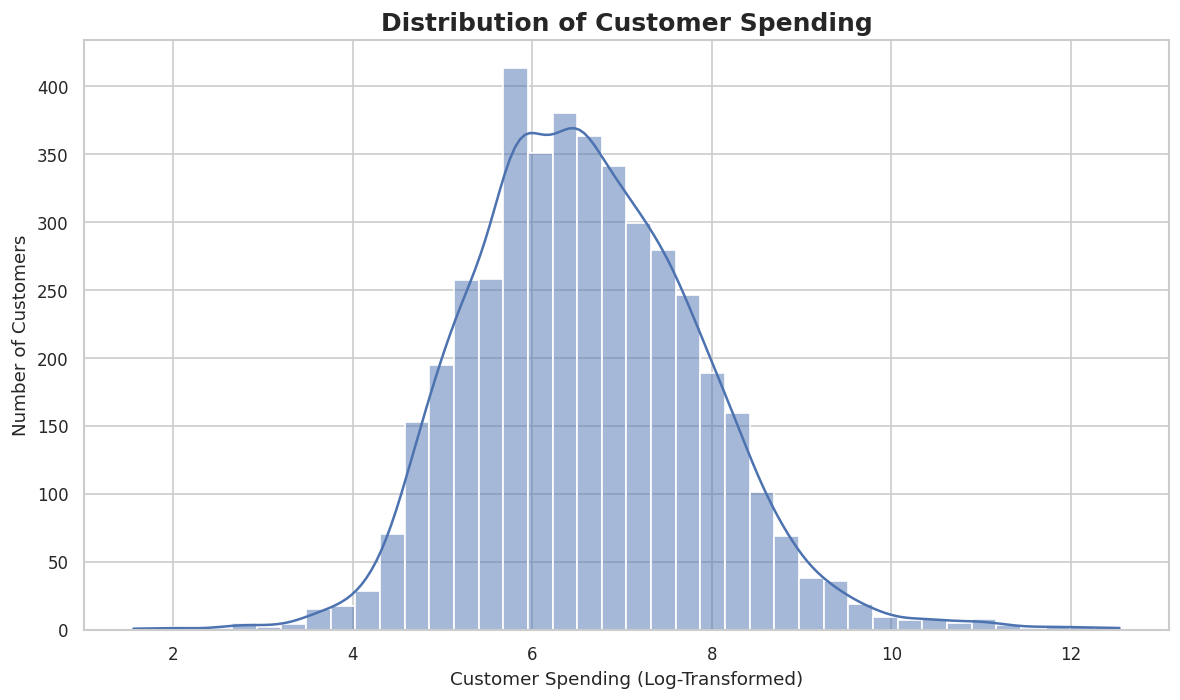

In [142]:

plt.figure(figsize=(10, 6))

sns.histplot(
    x=np.log1p(customer_data['TotalSpending']),
    bins=40,
    kde=True,
    color='#4C72B0',
    edgecolor='white'
)

plt.title('Distribution of Customer Spending', fontsize=15, fontweight='bold')
plt.xlabel('Customer Spending (Log-Transformed)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:**

The distribution of customer spending is positively skewed, indicating that most customers have relatively low-to-moderate spending levels, while a smaller number of customers contribute much higher spending amounts. The log transformation makes the distribution easier to visualize and reveals its overall pattern more clearly. This suggests that customers have different spending behaviors, which can be useful for identifying distinct customer segments.

In [143]:
customer_features = customer_data.copy()

In [144]:
customer_features['TotalSpending'] = np.log1p(customer_features['TotalSpending'])

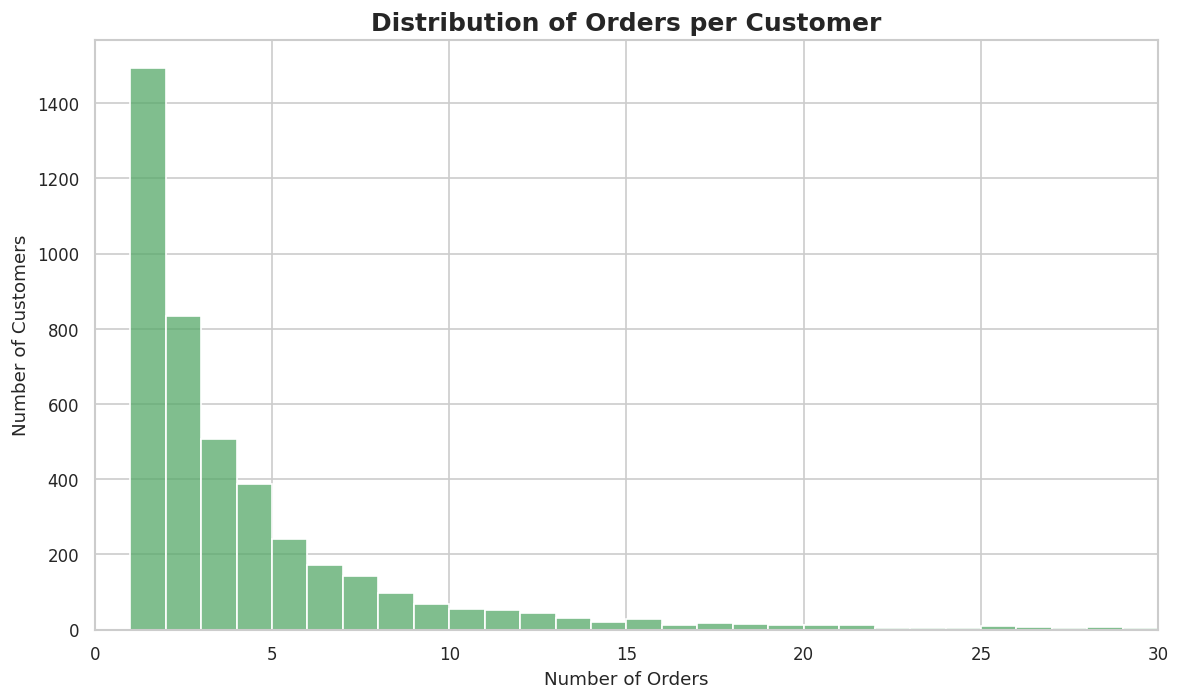

In [145]:

plt.figure(figsize=(10, 6))

upper_limit = customer_data['NumberOfOrders'].quantile(0.99)

sns.histplot(
    data=customer_data,
    x='NumberOfOrders',
    bins=30,
    binrange=(0, upper_limit),
    color='#55A868',
    edgecolor='white'
)

plt.xlim(0, upper_limit)
plt.title('Distribution of Orders per Customer',
          fontsize=15, fontweight='bold')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The distribution of orders per customer is positively skewed, indicating that most customers place relatively few orders, while a smaller group purchases more frequently. This variation in purchase frequency can help identify occasional buyers and regular customers during customer segmentation.

In [146]:
customer_features['NumberOfOrders'] = np.log1p(
    customer_features['NumberOfOrders']
)

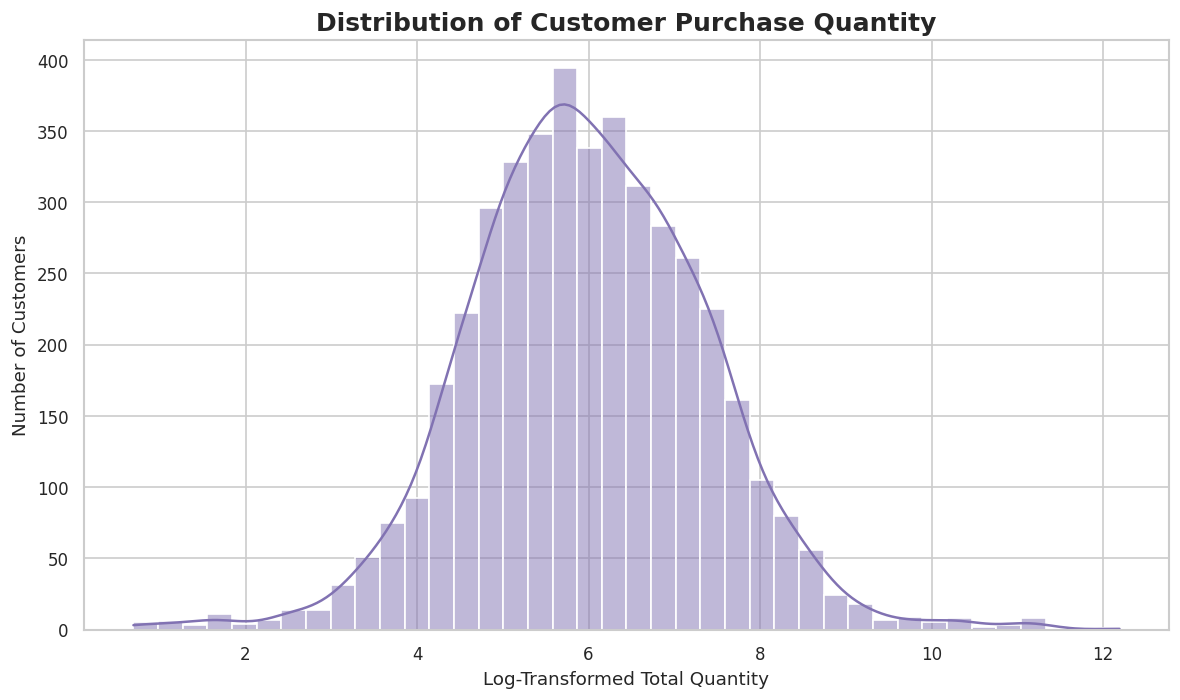

In [147]:

plt.figure(figsize=(10, 6))

sns.histplot(
    x=np.log1p(customer_data['TotalQuantity']),
    bins=40,
    kde=True,
    color='#8172B2',
    edgecolor='white'
)

plt.title('Distribution of Customer Purchase Quantity',
          fontsize=15, fontweight='bold')
plt.xlabel('Log-Transformed Total Quantity')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The log-transformed distribution of total quantity purchased shows that most customers purchase moderate quantities, while a smaller group purchases substantially larger quantities. The transformation reduces the impact of extreme values and makes the distribution easier to visualize. Differences in purchase quantity provide useful behavioral information for customer segmentation.

In [148]:
customer_features['TotalQuantity'] = np.log1p(
    customer_features['TotalQuantity']
)

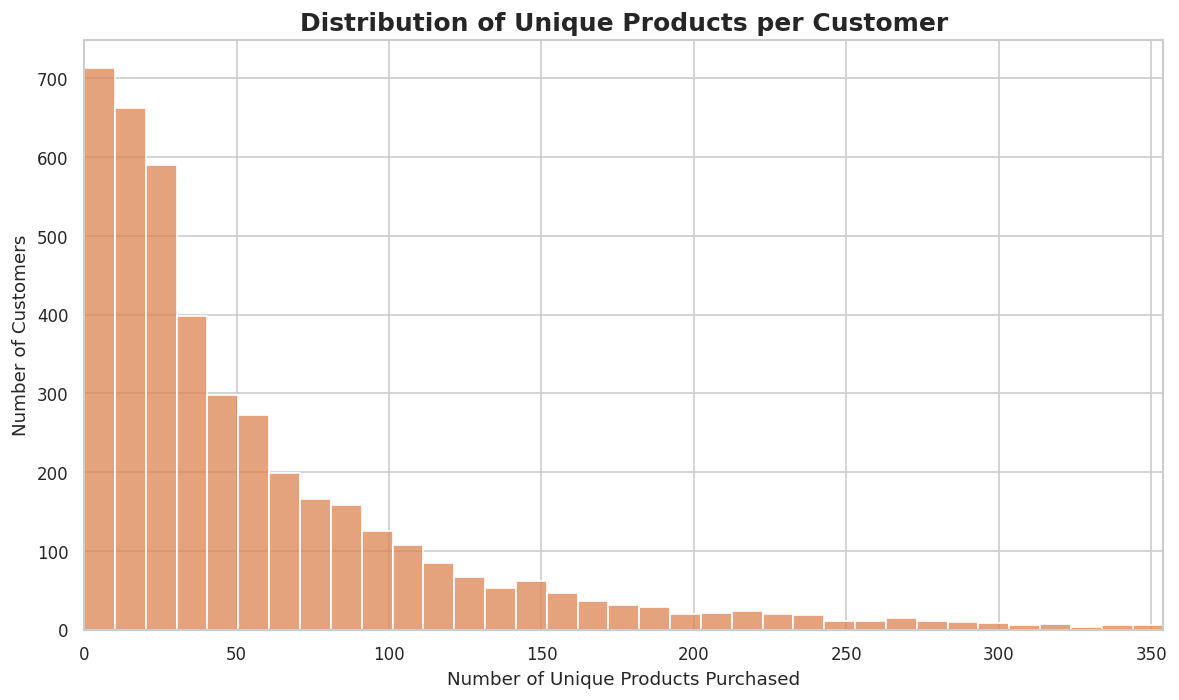

In [149]:

plt.figure(figsize=(10, 6))

upper_limit = customer_data['UniqueProducts'].quantile(0.99)

sns.histplot(
    data=customer_data,
    x='UniqueProducts',
    bins=35,
    binrange=(0, upper_limit),
    color='#DD8452',
    edgecolor='white'
)

plt.xlim(0, upper_limit)
plt.title('Distribution of Unique Products per Customer',
          fontsize=15, fontweight='bold')
plt.xlabel('Number of Unique Products Purchased')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The distribution of unique products purchased per customer is positively skewed. Most customers purchase a relatively limited variety of products, while a smaller group purchases a much wider range. This feature helps distinguish customers based on product variety and purchasing behavior.

In [150]:
customer_features['UniqueProducts'] = np.log1p(
    customer_features['UniqueProducts']
)

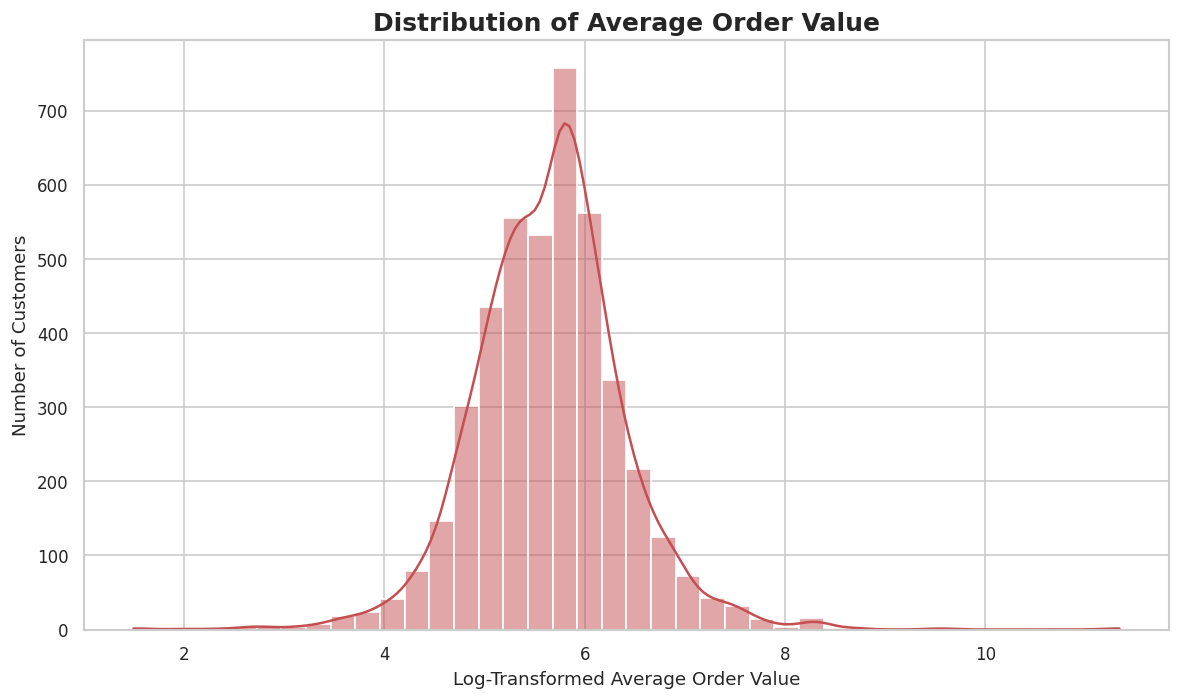

In [151]:

plt.figure(figsize=(10, 6))

sns.histplot(
    x=np.log1p(customer_data['AverageOrderValue']),
    bins=40,
    kde=True,
    color='#C44E52',
    edgecolor='white'
)

plt.title('Distribution of Average Order Value',
          fontsize=15, fontweight='bold')
plt.xlabel('Log-Transformed Average Order Value')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The log-transformed average order value distribution is concentrated around the middle range, with fewer customers at very low and very high values. This indicates variation in customers' average spending per transaction. Average order value complements total spending and order frequency by helping distinguish customers based on their typical transaction size.

In [152]:
customer_features['AverageOrderValue'] = np.log1p(
    customer_features['AverageOrderValue']
)

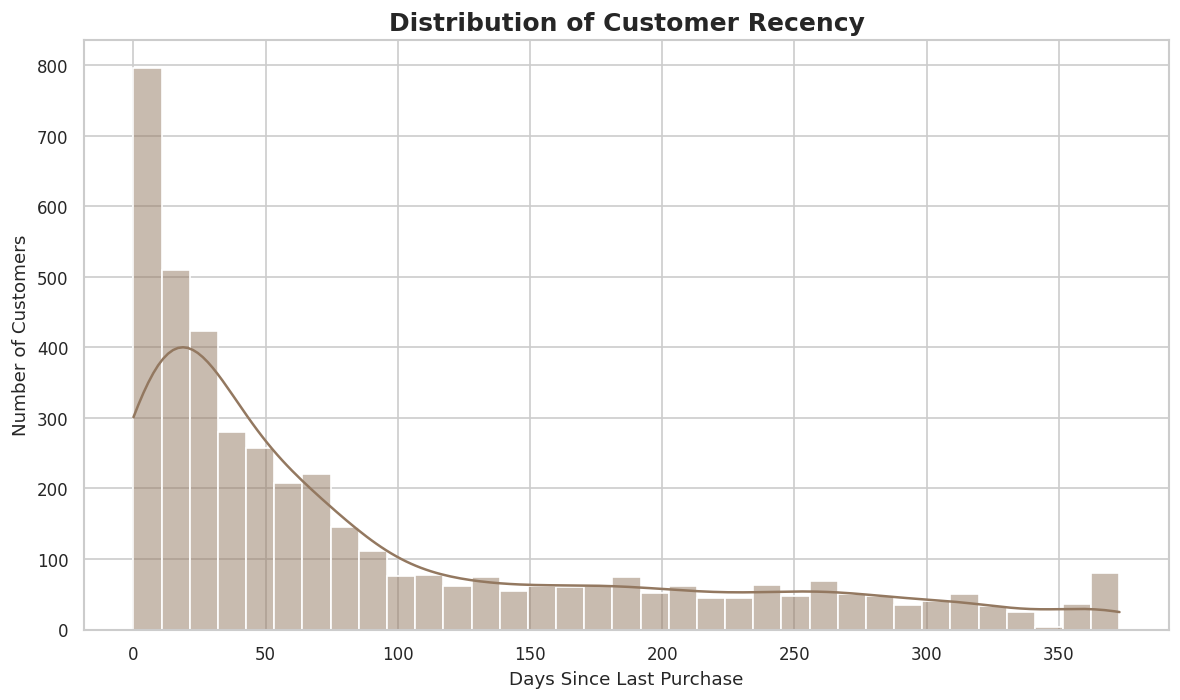

In [153]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_data,
    x='Recency',
    bins=35,
    kde=True,
    color='#937860',
    edgecolor='white'
)

plt.title('Distribution of Customer Recency',
          fontsize=15, fontweight='bold')
plt.xlabel('Days Since Last Purchase')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The distribution of recency is positively skewed, indicating that many customers made purchases relatively recently, while a smaller group has not purchased for a longer period. Customers with higher recency values may require re-engagement strategies, whereas customers with lower values appear more recently active. Recency is therefore an important feature for identifying customer activity patterns during segmentation.

In [154]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(customer_features)

print("Original feature shape:", customer_features.shape)
print("Scaled feature shape:", scaled_features.shape)


Original feature shape: (4338, 6)
Scaled feature shape: (4338, 6)


In [155]:
inertia_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)
    inertia_values.append(kmeans.inertia_)

print("Inertia values:", inertia_values)

Inertia values: [15131.342434710981, 11964.859610585583, 10328.868972424674, 9126.752899978865, 8178.886945352596, 7513.391698348251, 7034.207350561819, 6625.108337758263, 6303.242877673304]


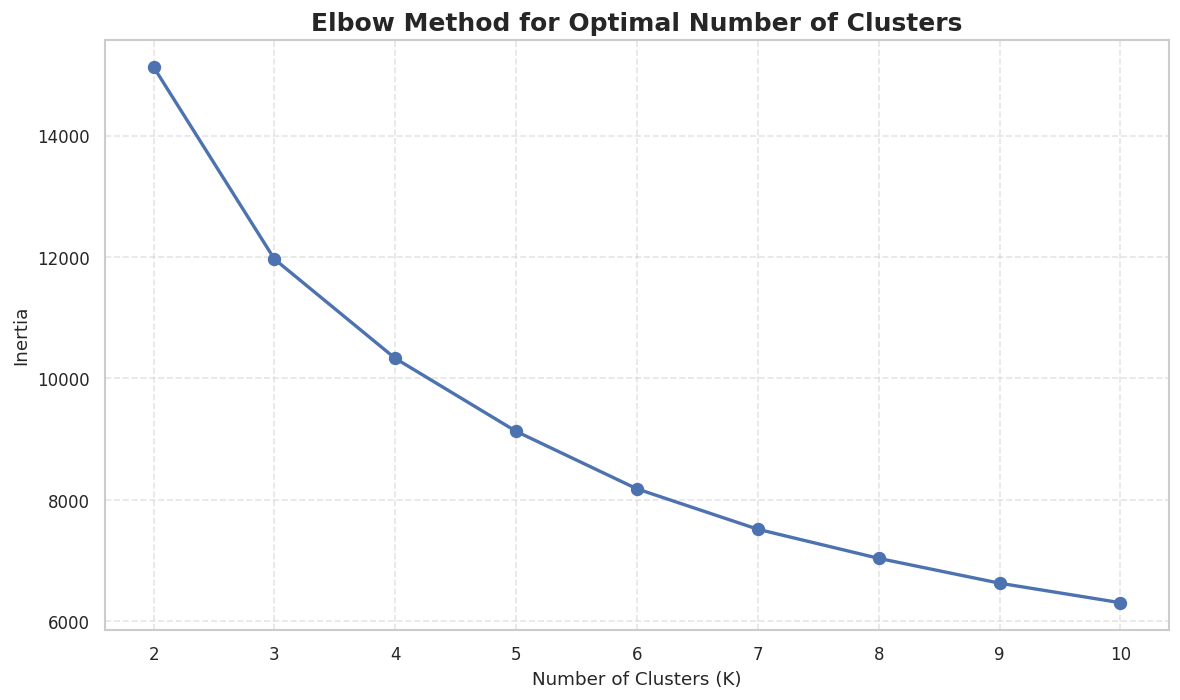

In [156]:

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o',
    markersize=7,
    linewidth=2,
    color='#4C72B0'
)

plt.title('Elbow Method for Optimal Number of Clusters',
          fontsize=15, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


**Inference:** The inertia decreases as the number of clusters increases, indicating that customers become more closely grouped within their clusters. The reduction is more noticeable between \(K=2\) and \(K=4\), after which the curve begins to flatten gradually. This suggests that \(K=4\) may be a reasonable candidate for customer segmentation. However, the final number of clusters should also be evaluated using the Silhouette Score and cluster interpretability.

In [157]:
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_features)

    score = silhouette_score(scaled_features, labels)
    silhouette_scores.append(score)

print("Silhouette scores:")

for k, score in zip(k_values, silhouette_scores):
    print(f"K = {k}: {score:.4f}")


Silhouette scores:
K = 2: 0.3513
K = 3: 0.2735
K = 4: 0.2587
K = 5: 0.2406
K = 6: 0.2457
K = 7: 0.2307
K = 8: 0.2165
K = 9: 0.2231
K = 10: 0.2169


In [158]:
final_k = 4

kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

customer_data['CustomerSegment'] = kmeans.fit_predict(scaled_features)

print("Number of clusters:", final_k)
print("\nCustomers in each cluster:")
print(customer_data['CustomerSegment'].value_counts().sort_index())


Number of clusters: 4

Customers in each cluster:
CustomerSegment
0     799
1    1652
2     940
3     947
Name: count, dtype: int64


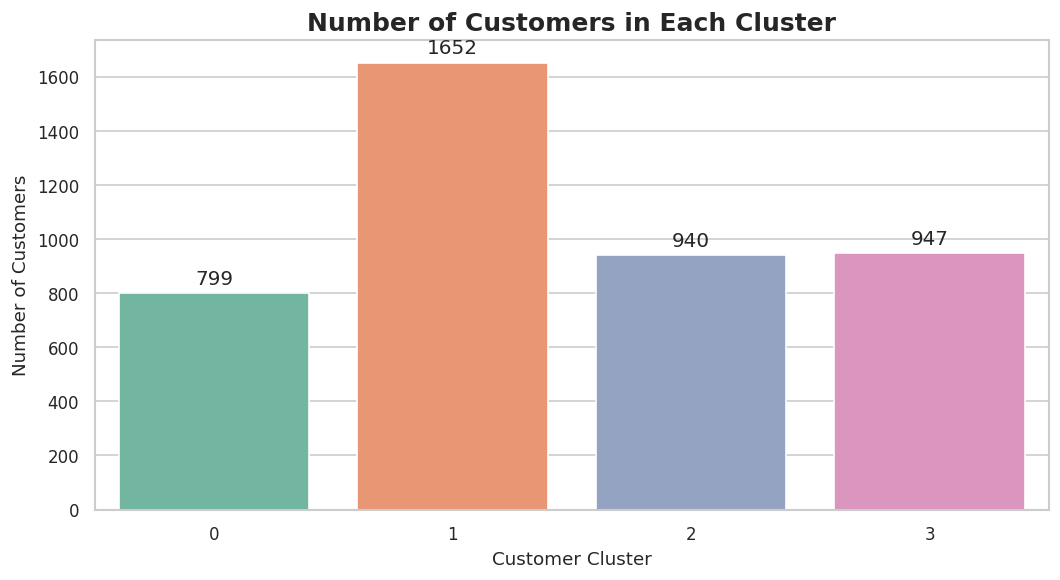

In [159]:

cluster_counts = customer_data['CustomerSegment'].value_counts().sort_index()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    hue=cluster_counts.index.astype(str),
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title('Number of Customers in Each Cluster',
          fontsize=15, fontweight='bold')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


**Inference:** The original transaction dataset contains 397,885 transaction records, which were aggregated into 4,338 unique customer profiles for segmentation. The four clusters contain 769, 1,168, 1,706, and 695 customers, respectively, totaling 4,338 customers. Cluster 2 is the largest, with 1,706 customers, while Cluster 3 is the smallest, with 695 customers. This graph shows the distribution of customers across clusters, not individual transaction records.

In [160]:
cluster_profiles = customer_data.groupby('CustomerSegment')[
    [
        'TotalSpending',
        'NumberOfOrders',
        'TotalQuantity',
        'UniqueProducts',
        'AverageOrderValue',
        'Recency'
    ]
].mean().round(2)

display(cluster_profiles)


,TotalSpending,NumberOfOrders,TotalQuantity,UniqueProducts,AverageOrderValue,Recency
CustomerSegment,,,,,,
0,310.50,1.29,165.44,17.87,254.78,266.74
1,1057.56,2.94,632.78,55.99,442.66,63.65
2,7087.97,11.76,4085.42,151.98,759.21,25.22
3,267.75,1.68,158.37,18.11,179.35,58.18


In [161]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

pca_components = pca.fit_transform(scaled_features)

customer_data['PCA1'] = pca_components[:, 0]
customer_data['PCA2'] = pca_components[:, 1]

print("Explained variance by PC1 and PC2:")
print(pca.explained_variance_ratio_.round(4))

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Explained variance by PC1 and PC2:
[0.6495 0.1665]
Total variance explained: 81.61 %


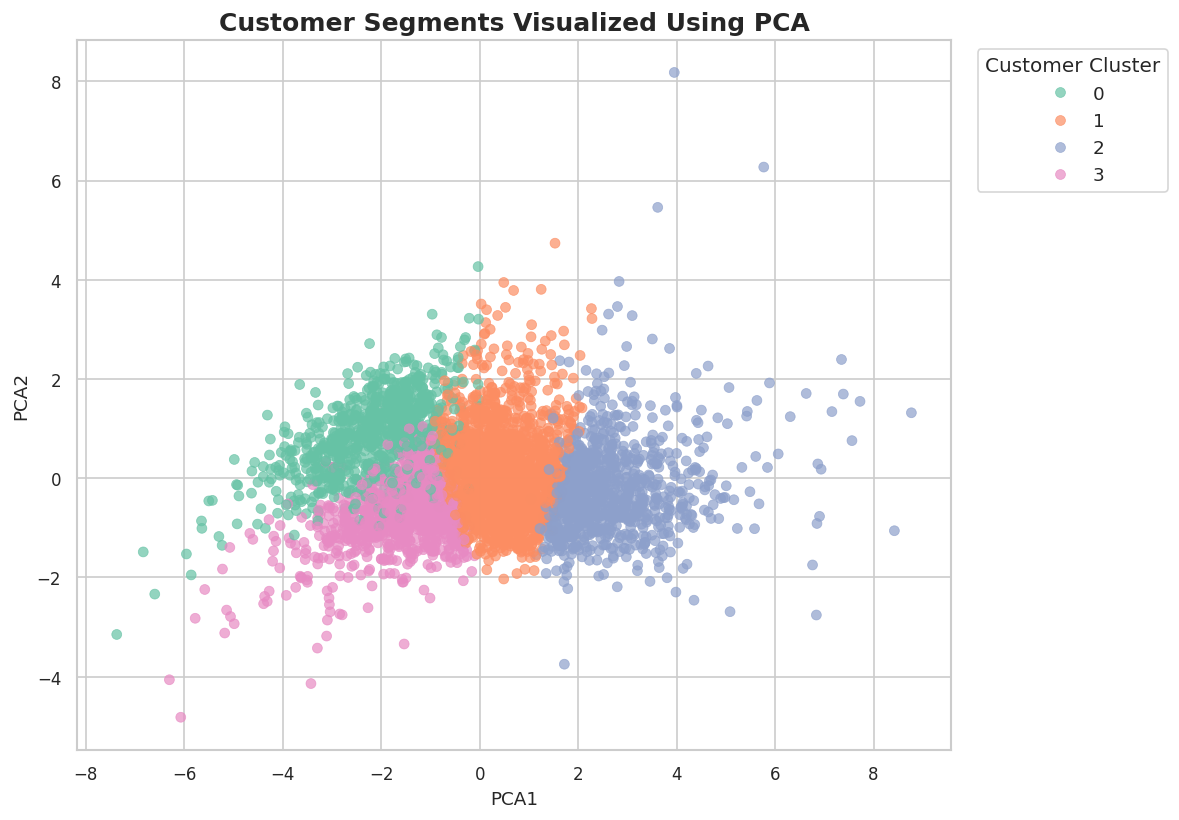

In [162]:

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=customer_data,
    x='PCA1',
    y='PCA2',
    hue='CustomerSegment',
    palette='Set2',
    s=35,
    alpha=0.7,
    edgecolor=None
)

plt.title('Customer Segments Visualized Using PCA',
          fontsize=15, fontweight='bold')
plt.xlabel('PCA1')
plt.ylabel('PCA2')

plt.legend(
    title='Customer Cluster',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


In [163]:

segment_names = {
    0: 'Low-Value Customers',
    1: 'High-Value Loyal Customers',
    2: 'Regular Customers',
    3: 'Inactive/At-Risk Customers'
}

customer_data['SegmentName'] = customer_data['CustomerSegment'].map(
    segment_names
)

print(customer_data[['CustomerSegment', 'SegmentName']].head())


            CustomerSegment                 SegmentName
CustomerID                                             
12346.0                   2           Regular Customers
12347.0                   2           Regular Customers
12348.0                   1  High-Value Loyal Customers
12349.0                   1  High-Value Loyal Customers
12350.0                   0         Low-Value Customers


In [164]:
display(
    customer_data[['CustomerSegment', 'SegmentName']].head(10)
)


,CustomerSegment,SegmentName
CustomerID,,
12346.0,2,Regular Customers
12347.0,2,Regular Customers
12348.0,1,High-Value Loyal Customers
12349.0,1,High-Value Loyal Customers
12350.0,0,Low-Value Customers
12352.0,2,Regular Customers
12353.0,0,Low-Value Customers
12354.0,1,High-Value Loyal Customers
12355.0,0,Low-Value Customers


In [165]:
segment_profiles = customer_data.groupby('SegmentName')[
    [
        'TotalSpending',
        'NumberOfOrders',
        'TotalQuantity',
        'UniqueProducts',
        'AverageOrderValue',
        'Recency'
    ]
].mean().round(2)

display(segment_profiles)


,TotalSpending,NumberOfOrders,TotalQuantity,UniqueProducts,AverageOrderValue,Recency
SegmentName,,,,,,
High-Value Loyal Customers,1057.56,2.94,632.78,55.99,442.66,63.65
Inactive/At-Risk Customers,267.75,1.68,158.37,18.11,179.35,58.18
Low-Value Customers,310.50,1.29,165.44,17.87,254.78,266.74
Regular Customers,7087.97,11.76,4085.42,151.98,759.21,25.22


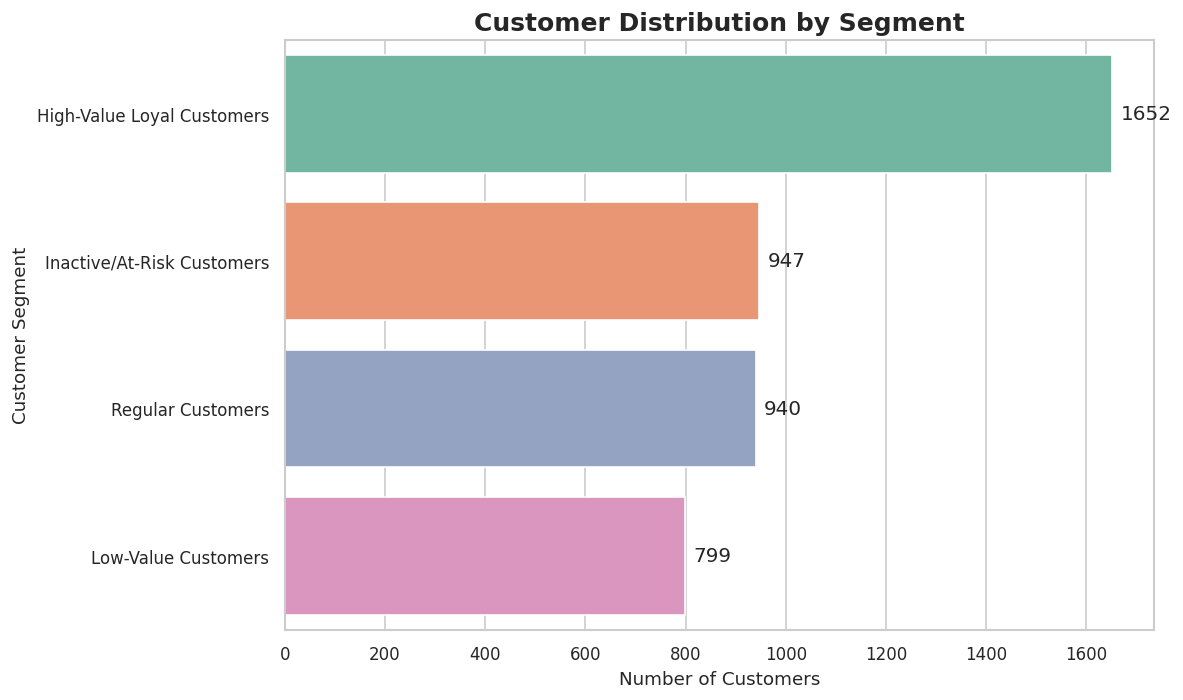

In [166]:
segment_counts = customer_data['SegmentName'].value_counts()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index,
    hue=segment_counts.index,
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=5)

plt.title('Customer Distribution by Segment', fontsize=15, fontweight='bold')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()


**Inference**
The graph shows the distribution of 4,338 customers across four segments. Regular Customers form the largest segment, with 1,706 customers, followed by High-Value Loyal Customers with 1,168. Low-Value Customers account for 769 customers, while Inactive/At-Risk Customers form the smallest segment, with 695 customers. These counts help identify the size of each customer group and support targeted marketing strategies.

In [167]:
business_recommendations = {
    'Low-Value Customers':
        'Encourage repeat purchases through personalized offers, product recommendations, and affordable bundles.',

    'High-Value Loyal Customers':
        'Reward valuable customers with loyalty benefits, exclusive offers, and personalized recommendations.',

    'Regular Customers':
        'Increase purchase frequency and spending through cross-selling, product suggestions, and loyalty programs.',

    'Inactive/At-Risk Customers':
        'Launch re-engagement campaigns with personalized discounts and reminders to encourage customers to return.'
}

for segment, recommendation in business_recommendations.items():
    print(f"\n{segment}")
    print(f"Recommendation: {recommendation}")



Low-Value Customers
Recommendation: Encourage repeat purchases through personalized offers, product recommendations, and affordable bundles.

High-Value Loyal Customers
Recommendation: Reward valuable customers with loyalty benefits, exclusive offers, and personalized recommendations.

Regular Customers
Recommendation: Increase purchase frequency and spending through cross-selling, product suggestions, and loyalty programs.

Inactive/At-Risk Customers
Recommendation: Launch re-engagement campaigns with personalized discounts and reminders to encourage customers to return.


In [168]:
output_file = 'customer_segmentation_results.csv'

customer_data.to_csv(output_file, index=False)

print(f"Customer segmentation results saved to: {output_file}")
print("Total customer records:", len(customer_data))
print("Total customer segments:", customer_data['SegmentName'].nunique())


Customer segmentation results saved to: customer_segmentation_results.csv
Total customer records: 4338
Total customer segments: 4


## Final Inference

K-Means clustering was used to segment 4,338 customers into four groups based on RFM and purchasing behavior. The segments identified were Low-Value Customers, High-Value Loyal Customers, Regular Customers, and Inactive/At-Risk Customers. The results reveal differences in spending, purchase frequency, and recency, helping businesses develop targeted marketing strategies, improve customer retention, and encourage repeat purchases.